# Utilización, procesamiento y visualización de grandes volúmenes de datos
## Alfredo Alejandro Soto Herrera - A01711368

Contexto:

Las tiendas digitales (Steam, PlayStation Store, Xbox Store, Nintendo eShop, etc.) cambian sus precios constantemente. Anticipar cuándo un juego va a entrar en oferta sirve tanto al consumidor (decidir si comprar hoy o esperar) como a las tiendas y editoras (planear su calendario de descuentos).

Dataset: https://www.kaggle.com/datasets/amith1707/video-game-market-price-and-revenue-dataset, archivo videogames_processed.csv.


## PASO 1: Configuración del entorno de trabajo

In [2]:
!pip install -q pyspark

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import glob
import time
import matplotlib.pyplot as plt
import pandas as pd

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, Imputer
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

In [4]:
BASE_DIR     = "/content/drive/My Drive/Concentracion_ia"
CSV_PATH     = f"{BASE_DIR}/videogames_processed.csv"
PARQUET_PATH = f"{BASE_DIR}/videogames_parquet"
MODEL_PATH   = f"{BASE_DIR}/modelo_rf_ofertas"
EXPORT_DIR   = f"{BASE_DIR}/tableau"

os.makedirs(EXPORT_DIR, exist_ok=True)
print("CSV existe:", os.path.exists(CSV_PATH))
print(f"Tamaño del CSV: {os.path.getsize(CSV_PATH) / 1024**3:.2f} GB")

CSV existe: True
Tamaño del CSV: 4.64 GB


In [5]:
spark = (SparkSession.builder
         .appName("Videojuegos_Ofertas_RF")
         .config("spark.driver.memory", "10g")
         .config("spark.sql.shuffle.partitions", "64")
         .getOrCreate())

spark.sparkContext.setLogLevel("ERROR")
print("Versión de Spark:", spark.version)
print("Núcleos disponibles:", spark.sparkContext.defaultParallelism)

Versión de Spark: 4.0.5
Núcleos disponibles: 12


## PASO 2: Carga de datos y justificación de Big Data


In [6]:
inicio = time.time()
df_raw = spark.read.csv(CSV_PATH, header=True, inferSchema=False)

n_filas = df_raw.count()
n_cols = len(df_raw.columns)
print(f"Filas: {n_filas:,}")
print(f"Columnas: {n_cols}")
print(f"Particiones: {df_raw.rdd.getNumPartitions()}")
print(f"Tiempo de lectura y conteo: {time.time() - inicio:.1f} s")

Filas: 5,584,706
Columnas: 130
Particiones: 38
Tiempo de lectura y conteo: 85.4 s


5,584,706 filas x 130 columnas (4.64 GB en CSV). Spark dividió el archivo en 38 particiones de 125 MB y reparte esas 38 tareas entre los 12 núcleos disponibles en unas 3 o 4 tandas, en lugar de leer el archivo de forma secuencial.

125 segundos solo para leer y contar. Un count() obliga a recorrer los 5 GB completos de texto; es justo el costo que se evita al convertir a Parquet en el siguiente paso, para no pagarlo en cada consulta.

### ¿Por qué este dataset justifica el uso de Big Data?

- Casi 5 GB en CSV, millones de filas y 130 columnas. Cargado en pandas, un DataFrame de este tamaño ocupa varias veces el tamaño del archivo en memoria, lo que excede la RAM de una computadora común o de Colab gratuito.
- Spark divide el archivo en particiones y las procesa en paralelo.
- 10,000 juegos observados repetidamente entre 2019 y 2024 en varias plataformas y tiendas. Cada fila es una observación de un juego en una fecha.

## PASO 3: Limpieza, conversión de tipos y almacenamiento en Parquet

### 3.1 Clasificación de columnas

In [7]:
# Columnas de texto o fechas que NO se convierten a número
COLS_TEXTO = [
    "game_id", "platform", "platform_code", "storefront", "obs_date",
    "sale_event_name", "game_name", "developer", "publisher", "publisher_tier",
    "franchise", "genre", "genre_code", "subgenre", "tags", "age_rating",
    "release_date", "subscription_service", "tier_label", "launch_phase",
    "controversy_day",
]
COLS_TEXTO = [c for c in COLS_TEXTO if c in df_raw.columns]
COLS_NUM = [c for c in df_raw.columns if c not in COLS_TEXTO]
print(f"Columnas de texto: {len(COLS_TEXTO)} | Columnas numéricas: {len(COLS_NUM)}")

Columnas de texto: 21 | Columnas numéricas: 109


In [8]:
def a_numero(c):
    v = F.lower(F.trim(F.col(c)))
    return (F.when(v.isin("true", "yes"), 1.0)
             .when(v.isin("false", "no"), 0.0)
             .when(v.isin("", "nan", "null", "none"), None)
             .when(v.rlike("^q[1-4]$"), F.substring(v, 2, 1).try_cast(DoubleType()))
             .otherwise(v.try_cast(DoubleType()))
             .alias(c))

def a_texto(c):
    v = F.trim(F.col(c))
    return F.when((v == "") | F.lower(v).isin("nan", "null"), None).otherwise(v).alias(c)

df_tipado = df_raw.select(
    [a_texto(c) for c in COLS_TEXTO] + [a_numero(c) for c in COLS_NUM]
).withColumn("obs_date", F.to_date("obs_date"))

### 3.2 Conversión a Parquet

El CSV es un formato de texto plano: cada lectura obliga a Spark a volver a interpretar 5 GB de texto.

La conversión se hace una sola vez y se guarda en Drive.

In [9]:
if not os.path.exists(f"{PARQUET_PATH}/_SUCCESS"):
    inicio = time.time()
    df_tipado.write.mode("overwrite").parquet(PARQUET_PATH)
    print(f"Parquet generado en {time.time() - inicio:.1f} s")
else:
    print("El Parquet ya existe, se reutiliza.")

df = spark.read.parquet(PARQUET_PATH)

tam_parquet = sum(os.path.getsize(f) for f in glob.glob(f"{PARQUET_PATH}/*.parquet"))
print(f"Tamaño CSV:     {os.path.getsize(CSV_PATH) / 1024**3:.2f} GB")
print(f"Tamaño Parquet: {tam_parquet / 1024**3:.2f} GB")

El Parquet ya existe, se reutiliza.
Tamaño CSV:     4.64 GB
Tamaño Parquet: 0.80 GB


- El Parquet pesa 0.80 GB frente a 4.64 GB del CSV, una reducción de 82.8%
- Al ser columnar, Spark lee únicamente las columnas que cada consulta necesita.
- Desde este punto, conteos, agrupaciones y entrenamiento parten del Parquet y no del CSV.

In [10]:
cols_double = [c for c, t in df.dtypes if t == "double"]

conteo_inf = df.select([
    F.sum((F.abs(F.col(c)) == float("inf")).cast("int")).alias(c) for c in cols_double
]).first().asDict()
conteo_inf = {c: v for c, v in conteo_inf.items() if v}
print("Columnas con valores infinitos:", conteo_inf if conteo_inf else "ninguna")

def limpiar_num(c):
    x = F.col(c)
    return F.when(F.isnan(x) | (F.abs(x) == float("inf")), None).otherwise(x).alias(c)

df = df.select([limpiar_num(c) if c in cols_double else F.col(c) for c in df.columns])

Columnas con valores infinitos: {'review_growth_rate': 2831, 'player_growth_rate': 6167}


### 3.3 Esquema y primeros registros

In [11]:
df.printSchema()

root
 |-- game_id: string (nullable = true)
 |-- platform: string (nullable = true)
 |-- platform_code: string (nullable = true)
 |-- storefront: string (nullable = true)
 |-- obs_date: date (nullable = true)
 |-- sale_event_name: string (nullable = true)
 |-- game_name: string (nullable = true)
 |-- developer: string (nullable = true)
 |-- publisher: string (nullable = true)
 |-- publisher_tier: string (nullable = true)
 |-- franchise: string (nullable = true)
 |-- genre: string (nullable = true)
 |-- genre_code: string (nullable = true)
 |-- subgenre: string (nullable = true)
 |-- tags: string (nullable = true)
 |-- age_rating: string (nullable = true)
 |-- release_date: string (nullable = true)
 |-- subscription_service: string (nullable = true)
 |-- tier_label: string (nullable = true)
 |-- launch_phase: string (nullable = true)
 |-- controversy_day: string (nullable = true)
 |-- days_since_release: double (nullable = true)
 |-- current_price_usd: double (nullable = true)
 |-- orig

In [12]:
df.select("game_name", "platform", "storefront", "obs_date", "current_price_usd",
          "discount_pct", "is_on_sale", "sale_event_name", "target_is_on_sale_next_obs").show(5, truncate=False)

+-------------+-------------+-----------------+----------+-----------------+------------+----------+---------------+--------------------------+
|game_name    |platform     |storefront       |obs_date  |current_price_usd|discount_pct|is_on_sale|sale_event_name|target_is_on_sale_next_obs|
+-------------+-------------+-----------------+----------+-----------------+------------+----------+---------------+--------------------------+
|Golden Signal|PlayStation 4|PlayStation Store|2023-10-24|34.99            |0.0         |0.0       |none           |0.0                       |
|Golden Signal|PlayStation 4|PlayStation Store|2023-10-27|34.99            |0.0         |0.0       |none           |1.0                       |
|Golden Signal|PlayStation 4|PlayStation Store|2023-11-08|17.99            |49.4        |1.0       |Autumn Sale    |0.0                       |
|Golden Signal|PlayStation 4|PlayStation Store|2023-11-10|34.99            |0.0         |0.0       |none           |0.0                 

### 3.4 Valores nulos

Las columnas con más del 50% de nulos se descartan más adelante

In [13]:
nulos = df.select([F.avg(F.col(c).isNull().cast("double")).alias(c) for c in df.columns]).toPandas().T
nulos.columns = ["pct_nulos"]
nulos = nulos.sort_values("pct_nulos", ascending=False)
print(nulos[nulos["pct_nulos"] > 0].round(4).to_string())

                             pct_nulos
subscription_service            0.3405
franchise                       0.0914
price_change_pct                0.0750
player_growth_rate              0.0338
review_growth_rate              0.0209
target_revenue_next_4w          0.0204
target_ccu_next_4w              0.0204
popularity_momentum             0.0204
target_price_next_4w            0.0204
target_review_count_next_4w     0.0204
price_change_abs                0.0051
price_volatility                0.0051


subscription_service (34.05 %) tiene el mayor porcentaje. Es probable que el nulo signifique que el juego no pertenece a ningún servicio de suscripción, más que un dato perdido; por eso se rellena con una categoría explícita ("Desconocido") y no con una imputación estadística.

## PASO 4: Análisis exploratorio

### 4.1 Variable objetivo

target_is_on_sale_next_obs vale 1 si el juego estará en oferta en la siguiente observación y 0 si no.

In [14]:
TARGET = "target_is_on_sale_next_obs"

dist = df.groupBy(TARGET).count().orderBy(TARGET).toPandas()
dist["porcentaje"] = (dist["count"] / dist["count"].sum() * 100).round(2)
print(dist.to_string(index=False))

 target_is_on_sale_next_obs   count  porcentaje
                        0.0 4637643       83.04
                        1.0  947063       16.96


La variable objetivo está desbalanceada: 83.04% de las observaciones no tendrán oferta frente a 16.96% que sí. Un modelo que siempre responda "no habrá oferta" ya obtendría un accuracy cercano a 83 %. Por eso el accuracy no basta para evaluar este problema y es necesario revisar precisión, recall, AUC y AUC-PR.

In [15]:
df.select(
    F.countDistinct("game_id").alias("juegos_distintos"),
    F.min("obs_date").alias("primera_observacion"),
    F.max("obs_date").alias("ultima_observacion"),
).show()

+----------------+-------------------+------------------+
|juegos_distintos|primera_observacion|ultima_observacion|
+----------------+-------------------+------------------+
|            9995|         2019-01-02|        2024-12-30|
+----------------+-------------------+------------------+



Son 9,995 juegos observados durante 6 años completos (2 de enero de 2019 a 30 de diciembre de 2024), con 28,634 series (juego + plataforma + tienda) y 5.58 millones de filas, cada serie tiene en promedio unas 195 observaciones, es decir, una observación cada 11 días.

### 4.2 Distribución por plataforma, tienda y género

In [16]:
for c in ["platform", "storefront", "genre"]:
    df.groupBy(c).count().orderBy(F.desc("count")).show(10, truncate=False)

+---------------+------+
|platform       |count |
+---------------+------+
|PC             |950711|
|Xbox One       |943119|
|Nintendo Switch|933910|
|Xbox Series X/S|924916|
|PlayStation 5  |923368|
|PlayStation 4  |908682|
+---------------+------+

+-----------------+-------+
|storefront       |count  |
+-----------------+-------+
|Xbox Store       |1868035|
|PlayStation Store|1832050|
|Steam            |950711 |
|Nintendo eShop   |933910 |
+-----------------+-------+

+--------------------+------+
|genre               |count |
+--------------------+------+
|Action              |698247|
|RPG                 |566448|
|First-Person Shooter|460538|
|Adventure           |420819|
|Strategy            |405737|
|Simulation          |357797|
|Sports              |340335|
|Indie               |316706|
|Platformer          |306398|
|Horror              |258109|
+--------------------+------+
only showing top 10 rows


- Plataformas: Casi balanceadas, entre 908,682 (PlayStation 4) y 950,711 (PC) observaciones; la diferencia entre la más y la menos observada es de apenas 4.6 %. Ninguna plataforma domina la muestra.
- Tiendas: Xbox Store (1.87 M) y PlayStation Store (1.83 M) tienen aproximadamente el doble que Steam y Nintendo eShop, pero solo porque cada una agrupa dos plataformas (Xbox One + Series X/S y PS4 + PS5). Por plataforma, el volumen es parejo, así que no hay un sesgo de tienda.
- Géneros: Action (12.5 %) y RPG (10.1 %) son los más frecuentes, seguidos de First-Person Shooter (8.2 %). Hay 18 géneros y el catálogo está bastante repartido, sin que unos cuantos géneros concentren la mayoría de las observaciones.

### 4.3 Comportamiento de las ofertas

Se compara el estado actual (is_on_sale) con el de la siguiente observación.

In [17]:
df.filter(F.col(TARGET).isNotNull()) \
  .groupBy("is_on_sale", TARGET).count() \
  .orderBy("is_on_sale", TARGET).show()

+----------+--------------------------+-------+
|is_on_sale|target_is_on_sale_next_obs|  count|
+----------+--------------------------+-------+
|       0.0|                       0.0|4158618|
|       0.0|                       1.0| 470847|
|       1.0|                       0.0| 479025|
|       1.0|                       1.0| 476216|
+----------+--------------------------+-------+



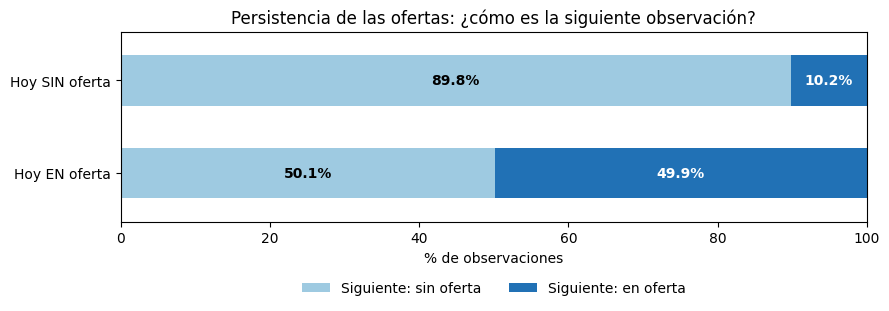

In [18]:
# Persistencia de las ofertas entre observaciones consecutivas
trans = (df.filter(F.col(TARGET).isNotNull())
           .groupBy("is_on_sale", TARGET).count().toPandas())
tabla = trans.pivot(index="is_on_sale", columns=TARGET, values="count").sort_index().sort_index(axis=1)
pct = tabla.div(tabla.sum(axis=1), axis=0) * 100      # % por fila: estado actual -> siguiente estado
pct.index = ["Hoy SIN oferta", "Hoy EN oferta"]
pct.columns = ["Siguiente: sin oferta", "Siguiente: en oferta"]

ax = pct.plot(kind="barh", stacked=True, figsize=(9, 3.4), color=["#9ecae1", "#2171b5"], width=0.55)
for cont, color in zip(ax.containers, ["black", "white"]):
    ax.bar_label(cont, fmt="%.1f%%", label_type="center", color=color, fontweight="bold")
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% de observaciones")
ax.set_title("Persistencia de las ofertas: ¿cómo es la siguiente observación?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
plt.tight_layout()
plt.show()


- Las ofertas son medianamente persistentes, si un juego está en oferta hoy, hay 49.9 % de probabilidad de que siga en oferta en la siguiente observación y 50.1 % de que termine.
- Las ofertas nuevas son poco frecuentes, si hoy no hay oferta, solo en 10.2 % de los casos habrá una en la siguiente observación. Estar en oferta hoy multiplica por 4.9 la probabilidad de estar en oferta después.

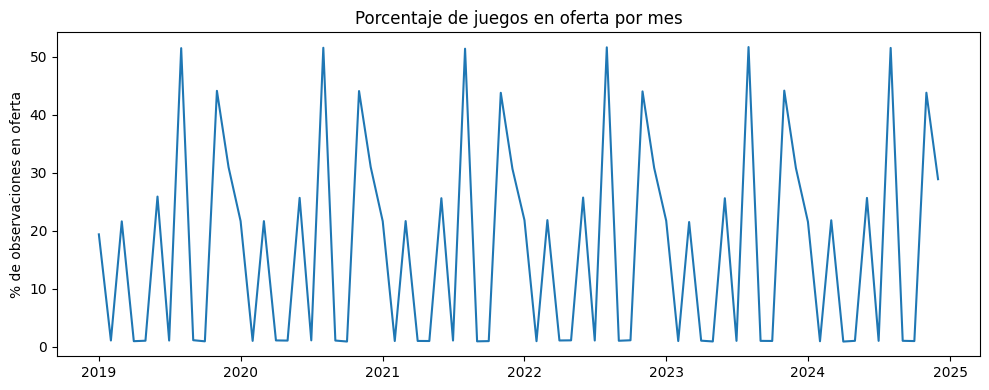

In [19]:
# Porcentaje de observaciones en oferta por mes
ofertas_mes = (df.groupBy("obs_year", "obs_month")
                 .agg(F.avg("is_on_sale").alias("pct_en_oferta"),
                      F.avg("discount_pct").alias("descuento_promedio"))
                 .orderBy("obs_year", "obs_month")
                 .toPandas())
ofertas_mes["fecha"] = pd.to_datetime(dict(year=ofertas_mes.obs_year.astype(int),
                                           month=ofertas_mes.obs_month.astype(int), day=1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ofertas_mes["fecha"], ofertas_mes["pct_en_oferta"] * 100)
ax.set_ylabel("% de observaciones en oferta")
ax.set_title("Porcentaje de juegos en oferta por mes")
plt.tight_layout()
plt.show()

- El patrón es fuertemente estacional y se repite igual cada año. La proporción de observaciones en oferta oscila entre 1% y 51%, con casi los mismos picos de 2019 a 2024.
- Picos principales: agosto (51%), noviembre (44%) y diciembre (31%); picos menores en enero, marzo y junio (22-26%).
- Hubo 6 meses casi sin ofertas (febrero, abril, mayo, julio, septiembre y octubre, 1%). Hay una diferencia de hasta 50 puntos porcentuales entre el mejor y el peor mes.
- No hay tendencia: El nivel de los picos no sube ni baja de un año a otro, es decir, el calendario promocional es estable.

In [20]:
# Descuento promedio por tienda y por evento de ventas
df.groupBy("storefront").agg(
    F.round(F.avg("is_on_sale") * 100, 2).alias("pct_en_oferta"),
    F.round(F.avg("discount_pct"), 2).alias("descuento_promedio"),
).orderBy(F.desc("pct_en_oferta")).show(truncate=False)

df.filter(F.col("is_on_sale") == 1).groupBy("sale_event_name").agg(
    F.count("*").alias("observaciones"),
    F.round(F.avg("discount_pct"), 2).alias("descuento_promedio"),
).orderBy(F.desc("observaciones")).show(15, truncate=False)

+-----------------+-------------+------------------+
|storefront       |pct_en_oferta|descuento_promedio|
+-----------------+-------------+------------------+
|PlayStation Store|17.15        |6.45              |
|Xbox Store       |17.1         |6.43              |
|Steam            |17.09        |6.45              |
|Nintendo eShop   |17.05        |6.41              |
+-----------------+-------------+------------------+

+---------------+-------------+------------------+
|sale_event_name|observaciones|descuento_promedio|
+---------------+-------------+------------------+
|Back to School |247875       |29.58             |
|Winter Sale    |151098       |48.71             |
|Autumn Sale    |136447       |32.49             |
|Summer Sale    |113615       |42.79             |
|Spring Sale    |93863        |32.12             |
|New Year Sale  |89394        |37.43             |
|Black Friday   |76145        |45.92             |
|Publisher Sale |46804        |45.04             |
+-------------

- Las tiendas son prácticamente idénticas: El porcentaje de observaciones en oferta va de 17.05% a 17.15% y el descuento promedio de 6.41% a 6.45%. Una diferencia de 0.1 puntos no es relevante, así que la tienda no ayuda a predecir ofertas. El descuento de 6.4 % es un promedio sobre todas las observaciones, incluidas las que no están en oferta. Entre las observaciones que sí están en oferta, el descuento promedio ronda el 37.6%.
- Los eventos se dividen en 2 tipos:
  - Frecuentes pero superficiales: "Back to School" concentra el 25.9 % de todas las observaciones en oferta, pero con un descuento promedio de solo 29.6%. Autumn Sale (32.5%) y Spring Sale (32.1%) tienen descuentos similares.
  - Menos frecuentes pero profundos: Winter Sale (48.7%), Black Friday (45.9%) y Publisher Sale (45.0%) ofrecen los descuentos más grandes, aunque con menos observaciones (15.8%, 8.0% y 4.9% del total).

## PASO 5: Selección de variables

Se excluyen:

| Grupo | Columnas | Motivo |
|---|---|---|
| Otros objetivos | todas las target_* | describen el futuro; usarlas sería hacer trampa (data leakage) |
| Identificadores | game_id, game_name | no generalizan, solo identifican |
| Texto con miles de valores | tags, developer, publisher, franchise | No aportan a un RandomForest |
| Duplicados | platform_code, genre_code | repiten platform y genre |
| Fechas crudas | obs_date, release_date, controversy_day | ya están desglosadas en obs_month, obs_year, release_year, etc. |

In [21]:
EXCLUIR = {
    "game_id", "game_name", "tags", "developer", "publisher", "franchise",
    "platform_code", "genre_code", "obs_date", "release_date", "controversy_day",
}
OBJETIVOS = [c for c in df.columns if c.startswith("target_")]
EXCLUIR |= set(OBJETIVOS)

# Se descartan las que tienen más de 50% de nulos
pct_nulos = nulos["pct_nulos"].to_dict()
numeric_cols = [c for c in COLS_NUM if c not in EXCLUIR and pct_nulos.get(c, 0) <= 0.5]

candidatas_cat = [c for c in COLS_TEXTO if c not in EXCLUIR]
cardinalidad = df.select([F.approx_count_distinct(c).alias(c) for c in candidatas_cat]).first().asDict()
categorical_cols = [c for c in candidatas_cat if cardinalidad[c] <= 100]

print("Cardinalidad de categóricas:", cardinalidad)
print(f"\nVariables categóricas ({len(categorical_cols)}): {categorical_cols}")
print(f"\nVariables numéricas ({len(numeric_cols)}): {numeric_cols}")
print(f"\nObjetivos excluidos: {OBJETIVOS}")

Cardinalidad de categóricas: {'platform': 6, 'storefront': 4, 'sale_event_name': 9, 'publisher_tier': 3, 'genre': 18, 'subgenre': 72, 'age_rating': 16, 'subscription_service': 6, 'tier_label': 3, 'launch_phase': 6}

Variables categóricas (10): ['platform', 'storefront', 'sale_event_name', 'publisher_tier', 'genre', 'subgenre', 'age_rating', 'subscription_service', 'tier_label', 'launch_phase']

Variables numéricas (101): ['days_since_release', 'current_price_usd', 'original_price_usd', 'discount_pct', 'is_on_sale', 'lowest_price_usd', 'decay_factor', 'price_vs_launch', 'concurrent_players', 'peak_ccu_alltime', 'review_count', 'positive_reviews', 'negative_reviews', 'steam_rating_pct', 'user_score', 'metacritic_score', 'wishlist_count', 'twitch_viewers_proxy', 'youtube_views_proxy', 'reddit_mentions', 'social_hype_index', 'has_controversy', 'estimated_units_sold', 'estimated_revenue_usd', 'revenue_per_review', 'revenue_per_player', 'price_na', 'price_eu', 'price_gb', 'price_jp', 'price_

---
## PASO 6: División temporal de los datos

Con una división aleatoria, observaciones casi idénticas del mismo juego quedarían en entrenamiento y prueba a la vez, y las métricas saldrían infladas.

Se usa una división temporal:

- Entrenamiento: Observaciones de 2019 a 2023.
- Prueba: Observaciones de 2024.

In [22]:
# Se conservan algunas columnas descriptivas para mostrar resultados
COLS_INFO = ["game_name", "obs_date", "platform", "storefront", "genre",
             "current_price_usd", "discount_pct", "is_on_sale"]
cols_seleccion = list(dict.fromkeys(categorical_cols + numeric_cols + COLS_INFO + [TARGET]))
df_modelo = df.select(cols_seleccion)
df_etiquetado = df_modelo.filter(F.col(TARGET).isNotNull()) \
                         .withColumn("label", F.col(TARGET).cast("double"))
df_sin_etiqueta = df_modelo.filter(F.col(TARGET).isNull())

# Las categóricas nulas se rellenan con una categoría explícita
df_etiquetado = df_etiquetado.fillna("Desconocido", subset=categorical_cols)
df_sin_etiqueta = df_sin_etiqueta.fillna("Desconocido", subset=categorical_cols)

ANIO_PRUEBA = 2024
train_data = df_etiquetado.filter(F.col("obs_year") < ANIO_PRUEBA)
test_data  = df_etiquetado.filter(F.col("obs_year") == ANIO_PRUEBA)

n_train, n_test = train_data.count(), test_data.count()
print(f"Train (2019-2023): {n_train:,} filas")
print(f"Test  (2024):      {n_test:,} filas")
print(f"Sin etiqueta:      {df_sin_etiqueta.count():,} filas")

train_data.groupBy("label").count().orderBy("label").show()

Train (2019-2023): 4,198,923 filas
Test  (2024):      1,385,783 filas
Sin etiqueta:      0 filas
+-----+-------+
|label|  count|
+-----+-------+
|  0.0|3469873|
|  1.0| 729050|
+-----+-------+



- La división temporal asigna 75.2% de los datos a entrenamiento (2019-2023, 4,198,923 filas) y 24.8% a prueba (2024, 1,385,783 filas). La prueba es un año completo que el modelo no vio, igual que ocurriría al usarlo en producción.
- Cambio en la proporción de ofertas: En entrenamiento 17.4% de las filas son positivas y en prueba 15.7%; es decir, 2024 tuvo ligeramente menos ofertas que el promedio histórico.
- En el conjunto de prueba, un modelo que siempre prediga sin oferta tendría un accuracy de 84.27% (1,167,770 de 1,385,783). Cualquier modelo debe compararse contra ese número, no contra el 50%.

In [23]:
FRACCION_TRAIN = 1.0

if FRACCION_TRAIN < 1.0:
    train_data = train_data.sample(fraction=FRACCION_TRAIN, seed=42)

from pyspark import StorageLevel
train_data = train_data.persist(StorageLevel.MEMORY_AND_DISK)
print(f"Filas usadas para entrenar: {train_data.count():,}")

Filas usadas para entrenar: 4,198,923


## PASO 7: ML Pipeline

Todas las transformaciones se encadenan en un único Pipeline.

| Etapa | Transformador | Función |
|---|---|---|
| 1 | StringIndexer | Convierte cada categoría en un índice numérico |
| 2 | OneHotEncoder | Convierte los índices en vectores binarios |
| 3 | Imputer | Rellena nulos numéricos con la mediana del entrenamiento |
| 4 | VectorAssembler | Une todo en un solo vector |
| 5 | RandomForestClassifier | Modelo de clasificación |

### 7.1 StringIndexer y OneHotEncoder para las variables categóricas

In [24]:
indexers = [
    StringIndexer(inputCol=c, outputCol=f"{c}_index", handleInvalid="keep")
    for c in categorical_cols
]
encoders = [
    OneHotEncoder(inputCol=f"{c}_index", outputCol=f"{c}_vec")
    for c in categorical_cols
]

### 7.2 Imputer para las variables numéricas

In [25]:
imputed_cols = [f"{c}_imp" for c in numeric_cols]
imputer = Imputer(inputCols=numeric_cols, outputCols=imputed_cols, strategy="median")

### 7.3 VectorAssembler

In [26]:
assembler_inputs = [f"{c}_vec" for c in categorical_cols] + imputed_cols
assembler = VectorAssembler(inputCols=assembler_inputs, outputCol="features", handleInvalid="keep")
print(f"Columnas de entrada del assembler: {len(assembler_inputs)}")

Columnas de entrada del assembler: 111


## PASO 8: Entrenamiento del modelo RandomForest

In [27]:
rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=50,
    maxDepth=10,
    seed=42,
)

pipeline = Pipeline(stages=indexers + encoders + [imputer, assembler, rf])

inicio = time.time()
model = pipeline.fit(train_data)
print(f"Tiempo de entrenamiento: {(time.time() - inicio) / 60:.1f} min")

Tiempo de entrenamiento: 4.3 min


## PASO 9: Evaluación del modelo

Se evalúa sobre el conjunto de prueba (2024), que el modelo nunca vio.

In [28]:
predictions = model.transform(test_data).persist(StorageLevel.MEMORY_AND_DISK)

predictions.select("game_name", "obs_date", "is_on_sale", "label", "prediction", "probability") \
           .show(10, truncate=False)

+-------------+----------+----------+-----+----------+----------------------------------------+
|game_name    |obs_date  |is_on_sale|label|prediction|probability                             |
+-------------+----------+----------+-----+----------+----------------------------------------+
|Golden Signal|2024-01-03|1.0       |1.0  |0.0       |[0.6610421246338501,0.33895787536614996]|
|Golden Signal|2024-01-05|1.0       |0.0  |0.0       |[0.646746281301107,0.3532537186988929]  |
|Golden Signal|2024-01-15|0.0       |0.0  |0.0       |[0.9408299290405203,0.05917007095947971]|
|Golden Signal|2024-01-20|0.0       |0.0  |0.0       |[0.9263563669929554,0.07364363300704452]|
|Golden Signal|2024-01-21|0.0       |0.0  |0.0       |[0.9263563669929554,0.07364363300704452]|
|Golden Signal|2024-01-24|0.0       |0.0  |0.0       |[0.9257771829368181,0.07422281706318185]|
|Golden Signal|2024-02-03|0.0       |0.0  |0.0       |[0.9250521177324305,0.07494788226756956]|
|Golden Signal|2024-02-09|0.0       |0.0

Golden Signal el 3 y el 5 de enero recibe probabilidades casi iguales (0.339 y 0.353), pero el resultado real fue distinto (1.0 y 0.0). Ambas observaciones estaban en oferta y los datos no traen una señal que permita saber en cuál de las dos continuará. En cambio, las observaciones sin oferta (15 y 20 de enero) reciben probabilidades de 0.06-0.07, unas 5 veces menos. El modelo distingue bien si hay una oferta activa de no la hay, pero le cuesta saber cuándo terminará una oferta.

### 9.1 Área bajo la curva ROC (AUC)

In [29]:
evaluator = BinaryClassificationEvaluator(
    labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC"
)
auc = evaluator.evaluate(predictions)
auc_pr = BinaryClassificationEvaluator(
    labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR"
).evaluate(predictions)
print(f"Área bajo la curva ROC (AUC): {auc:.4f}")
print(f"Área bajo la curva Precision-Recall: {auc_pr:.4f}")

Área bajo la curva ROC (AUC): 0.8169
Área bajo la curva Precision-Recall: 0.4182


- AUC-ROC = 0.8169. Si se toma al azar una observación que tendrá oferta y otra que no, el modelo asigna una probabilidad mayor a la primera en 81.7 % de los casos. Es una capacidad de discriminación buena.
- AUC-PR = 0.4182. La referencia de un modelo aleatorio es la proporción de positivos en prueba (0.157), así que el modelo es 2.7 veces mejor que el azar. Sin embargo, 0.42 en términos absolutos es moderado.

### 9.2 Accuracy, F1, precisión, recall y matriz de confusión

In [30]:
def metricas(pred_df, pred_col="prediction"):
    ev = lambda m, **kw: MulticlassClassificationEvaluator(
        labelCol="label", predictionCol=pred_col, metricName=m, **kw).evaluate(pred_df)
    return {
        "accuracy": ev("accuracy"),
        "f1": ev("f1"),
        "precision_oferta": ev("precisionByLabel", metricLabel=1.0),
        "recall_oferta": ev("recallByLabel", metricLabel=1.0),
    }

m_modelo = metricas(predictions)
for k, v in m_modelo.items():
    print(f"{k:<18}: {v:.4f}")

print("\nMatriz de confusión (label vs prediction):")
predictions.groupBy("label", "prediction").count().orderBy("label", "prediction").show()

accuracy          : 0.8499
f1                : 0.8261
precision_oferta  : 0.5490
recall_oferta     : 0.2562

Matriz de confusión (label vs prediction):
+-----+----------+-------+
|label|prediction|  count|
+-----+----------+-------+
|  0.0|       0.0|1121891|
|  0.0|       1.0|  45879|
|  1.0|       0.0| 162163|
|  1.0|       1.0|  55850|
+-----+----------+-------+



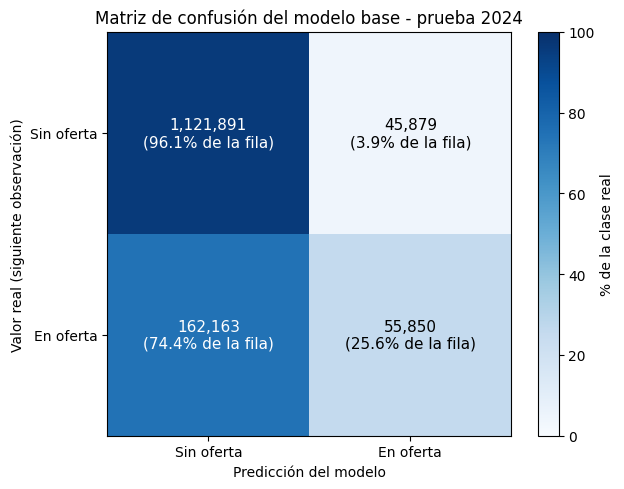

In [31]:
# Matriz de confusión del modelo base (conteos y % por clase real)
# `predictions` conserva las predicciones del modelo base (el ajustado se guardó en `pred_best`)
cm = (predictions.groupBy("label", "prediction").count().toPandas()
        .pivot(index="label", columns="prediction", values="count").sort_index().sort_index(axis=1))
import numpy as np
cm_pct = cm.div(cm.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(cm_pct.values, cmap="Blues", vmin=0, vmax=100)
etiquetas = ["Sin oferta", "En oferta"]
ax.set_xticks([0, 1]); ax.set_xticklabels(etiquetas)
ax.set_yticks([0, 1]); ax.set_yticklabels(etiquetas)
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Valor real (siguiente observación)")
ax.set_title("Matriz de confusión del modelo base - prueba 2024")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm.values[i, j]:,.0f}\n({cm_pct.values[i, j]:.1f}% de la fila)",
                ha="center", va="center", fontsize=11,
                color="white" if cm_pct.values[i, j] > 50 else "black")
fig.colorbar(im, ax=ax, label="% de la clase real")
plt.tight_layout()
plt.show()


- Acierta el 96.1% de las observaciones sin oferta (solo 3.9 % de falsos positivos).
- Detecta únicamente 25.6% (recall) de las ofertas reales; 162,163 ofertas no fueron detectadas.
- El accuracy engaña, 84.99% suena alto, pero la regla trivial de nunca habrá oferta logra 84.27%. La mejora real es de solo 0.7 puntos porcentuales. El F1 ponderado (0.8261) tampoco es informativo aquí porque lo domina la clase mayoritaria, el F1 de la clase oferta es de solo 0.349.
- Con clases 83/17 y un umbral estándar de 0.5, el modelo pocas veces llega a asignar una probabilidad superior a 0.5 a la clase minoritaria. Es un comportamiento esperable del Random Forest sin ajuste de umbral ni pesos de clase.
- Bajar el umbral aumentaría el recall (más ofertas detectadas) a costa de la precisión (más falsas alarmas). Un consumidor que no quiere perder ninguna oferta preferiría un recall alto, una tienda que planea su calendario preferiría una precisión alta.

### 9.3 Comparación contra el baseline

La regla ingenua "la siguiente observación tendrá el mismo estado que la actual" es el mínimo que el modelo debe superar. Si el RandomForest no la supera, significaría que solo está copiando el estado actual.

In [32]:
baseline = predictions.withColumn("pred_baseline", F.col("is_on_sale").cast("double")) \
                      .fillna(0.0, subset=["pred_baseline"])
m_base = metricas(baseline, "pred_baseline")

comparacion = pd.DataFrame({"Baseline (estado actual)": m_base, "RandomForest": m_modelo}).round(4)
print(comparacion.to_string())

                  Baseline (estado actual)  RandomForest
accuracy                            0.8258        0.8499
f1                                  0.8282        0.8261
precision_oferta                    0.4499        0.5490
recall_oferta                       0.4824        0.2562


El Random Forest no supera claramente al baseline, gana en accuracy y precisión, pero pierde en recall y en F1 de la clase de interés cuando se clasifica con el umbral de 0.5. El baseline atrapa las ofertas que continúan pero nunca puede anticipar una oferta nueva, ya que predice sin oferta para toda observación sin oferta. El modelo es más selectivo, avisa menos veces, pero con mayor certeza.

## PASO 10: Ajuste de hiperparámetros con TrainValidationSplit

In [33]:
FRACCION_TUNING = 0.1
train_tuning = train_data.sample(fraction=FRACCION_TUNING, seed=7)
print(f"Filas para la búsqueda de hiperparámetros: {train_tuning.count():,}")

param_grid = (ParamGridBuilder()
    .addGrid(rf.numTrees, [30, 60])
    .addGrid(rf.maxDepth, [8, 12])
    .addGrid(rf.minInstancesPerNode, [1, 20])
    .build())

tvs = TrainValidationSplit(
    estimator=pipeline,
    estimatorParamMaps=param_grid,
    evaluator=evaluator,
    trainRatio=0.8,
    parallelism=2,
    seed=42,
)

inicio = time.time()
tvs_model = tvs.fit(train_tuning)
print(f"Tiempo de búsqueda: {(time.time() - inicio) / 60:.1f} min")

resultados = sorted(zip(tvs_model.validationMetrics, param_grid), key=lambda x: -x[0])
for metrica, params in resultados:
    print(f"AUC validación={metrica:.4f} -> { {p.name: v for p, v in params.items()} }")

Filas para la búsqueda de hiperparámetros: 420,130
Tiempo de búsqueda: 5.2 min
AUC validación=0.8527 -> {'numTrees': 60, 'maxDepth': 12, 'minInstancesPerNode': 1}
AUC validación=0.8453 -> {'numTrees': 60, 'maxDepth': 12, 'minInstancesPerNode': 20}
AUC validación=0.8441 -> {'numTrees': 30, 'maxDepth': 12, 'minInstancesPerNode': 1}
AUC validación=0.8427 -> {'numTrees': 30, 'maxDepth': 12, 'minInstancesPerNode': 20}
AUC validación=0.8396 -> {'numTrees': 60, 'maxDepth': 8, 'minInstancesPerNode': 1}
AUC validación=0.8371 -> {'numTrees': 30, 'maxDepth': 8, 'minInstancesPerNode': 1}
AUC validación=0.8365 -> {'numTrees': 60, 'maxDepth': 8, 'minInstancesPerNode': 20}
AUC validación=0.8343 -> {'numTrees': 30, 'maxDepth': 8, 'minInstancesPerNode': 20}


In [34]:
mejores = {p.name: v for p, v in resultados[0][1].items()}
print("Mejores hiperparámetros:", mejores)

rf_final = RandomForestClassifier(labelCol="label", featuresCol="features", seed=42, **mejores)
pipeline_final = Pipeline(stages=indexers + encoders + [imputer, assembler, rf_final])

inicio = time.time()
best_model = pipeline_final.fit(train_data)
print(f"Tiempo de entrenamiento del modelo final: {(time.time() - inicio) / 60:.1f} min")

pred_best = best_model.transform(test_data).persist(StorageLevel.MEMORY_AND_DISK)
auc_best = evaluator.evaluate(pred_best)
m_best = metricas(pred_best)

comparacion["RF ajustado"] = pd.Series(m_best).round(4)
print(f"\nAUC modelo base   : {auc:.4f}")
print(f"AUC modelo ajustado: {auc_best:.4f}\n")
print(comparacion.to_string())

Mejores hiperparámetros: {'numTrees': 60, 'maxDepth': 12, 'minInstancesPerNode': 1}
Tiempo de entrenamiento del modelo final: 6.3 min

AUC modelo base   : 0.8169
AUC modelo ajustado: 0.8245

                  Baseline (estado actual)  RandomForest  RF ajustado
accuracy                            0.8258        0.8499       0.8501
f1                                  0.8282        0.8261       0.8274
precision_oferta                    0.4499        0.5490       0.5485
recall_oferta                       0.4824        0.2562       0.2652


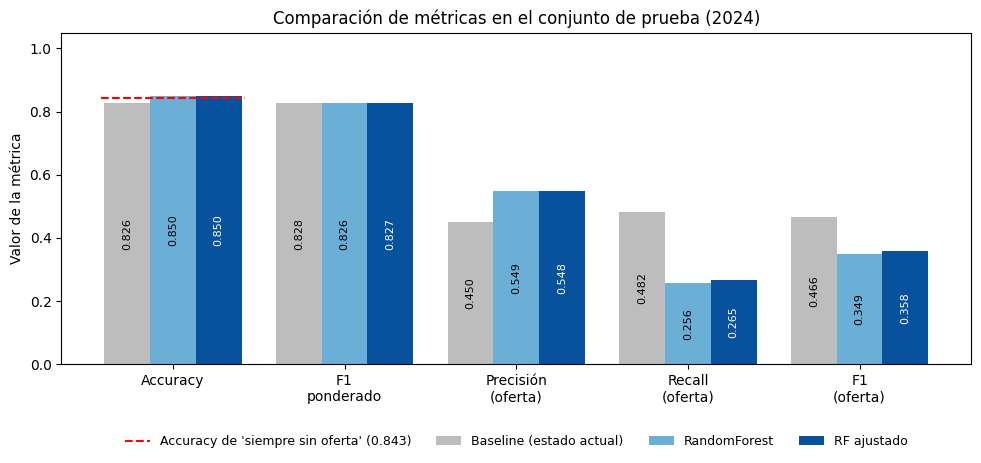

In [35]:
# Comparación de métricas (baseline vs. modelo base vs. modelo ajustado)
# Accuracy de la regla trivial "siempre predecir: sin oferta" sobre el conjunto de prueba
acc_trivial = 1 - test_data.agg(F.avg("label")).first()[0]
comp = comparacion.copy()
comp.loc["f1_oferta"] = (2 * comp.loc["precision_oferta"] * comp.loc["recall_oferta"]
                         / (comp.loc["precision_oferta"] + comp.loc["recall_oferta"]))
comp = comp.loc[["accuracy", "f1", "precision_oferta", "recall_oferta", "f1_oferta"]]
comp.index = ["Accuracy", "F1\nponderado", "Precisión\n(oferta)", "Recall\n(oferta)", "F1\n(oferta)"]

ax = comp.plot(kind="bar", figsize=(10, 4.8), width=0.8, color=["#bdbdbd", "#6baed6", "#08519c"])
for cont, color in zip(ax.containers, ["black", "black", "white"]):
    ax.bar_label(cont, fmt="%.3f", label_type="center", fontsize=8, color=color, rotation=90)
ax.hlines(acc_trivial, -0.42, 0.42, colors="red", linestyles="--", linewidth=1.5,
          label=f"Accuracy de 'siempre sin oferta' ({acc_trivial:.3f})")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Comparación de métricas en el conjunto de prueba (2024)")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.show()


- Accuracy: Los 3 quedan en una banda estrecha (0.826-0.850) y la línea roja (0.843) muestra que el modelo apenas la supera, mientras que el baseline queda por debajo de la regla trivial.
- Precisión vs. recall: Las barras se cruzan. El Random Forest (base y ajustado) tiene la mayor precisión, pero el baseline tiene casi el doble de recall. No hay un modelo mejor en todo; depende de qué error se quiere evitar.
- F1 de la clase oferta: El baseline (0.466) queda por encima del Random Forest (0.349 base, 0.358 ajustado), lo que confirma que, con un umbral de 0.5, el modelo es demasiado conservador.
- Base vs. ajustado: Las barras son casi idénticas; el ajuste de hiperparámetros movió las métricas por menos de 1 punto.

In [36]:
# Se conserva el mejor de los dos modelos según el AUC en prueba
if auc_best < auc:
    print("El modelo base tuvo mejor AUC en prueba; se conserva el modelo base.")
    best_model, pred_best, auc_best = model, predictions, auc
else:
    print("Se conserva el modelo ajustado.")

Se conserva el modelo ajustado.


## PASO 11: Importancia de variables

In [37]:
rf_model = best_model.stages[-1]

attrs = pred_best.schema["features"].metadata["ml_attr"]["attrs"]
idx_names = sorted([(a["idx"], a["name"]) for group in attrs.values() for a in group])
feature_names = [n.replace("_imp", "") for _, n in idx_names]

importancias = sorted(zip(feature_names, rf_model.featureImportances.toArray()), key=lambda x: -x[1])
for nombre, imp in importancias[:20]:
    print(f"{nombre:<45} {imp:.4f}")

sale_event_name_vec_none                      0.1502
obs_month                                     0.1101
is_on_sale                                    0.1014
discount_intensity                            0.0838
discount_pct                                  0.0629
price_vs_launch                               0.0552
sale_event_name_vec_Winter Sale               0.0547
launch_price_decay                            0.0539
sale_event_name_vec_Back to School            0.0463
price_change_pct                              0.0455
obs_quarter                                   0.0379
is_q4                                         0.0304
is_summer                                     0.0270
price_change_abs                              0.0262
sale_event_name_vec_Black Friday              0.0089
price_7obs_avg                                0.0075
price_jp                                      0.0068
discount_frequency_proxy                      0.0064
base_price_usd                                

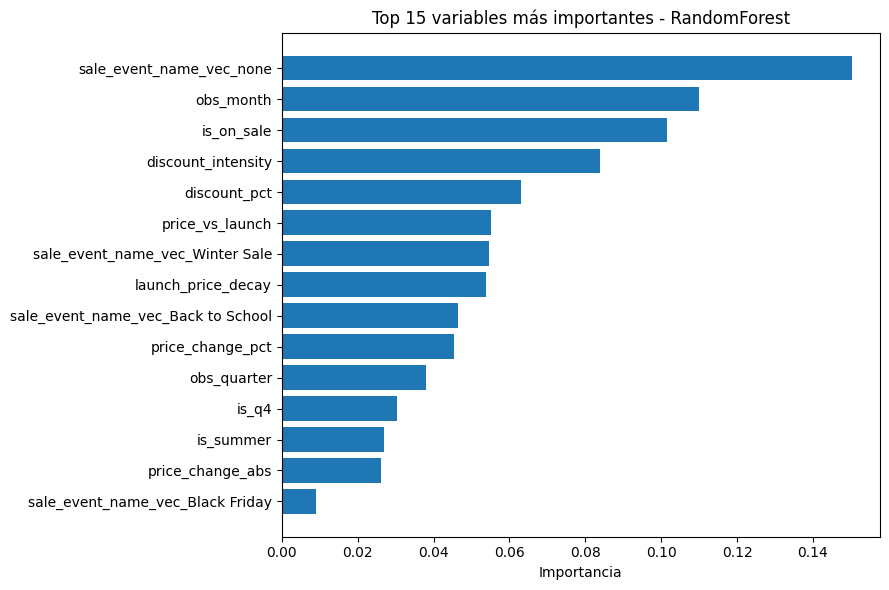

In [38]:
nombres, valores = zip(*importancias[:15])
plt.figure(figsize=(9, 6))
plt.barh(nombres[::-1], valores[::-1])
plt.xlabel("Importancia")
plt.title("Top 15 variables más importantes - RandomForest")
plt.tight_layout()
plt.show()

La variable más importante es sale_event_name_vec_none (0.150), que indica si en este momento no hay un evento de ventas activo. Le sigue obs_month (0.110), el mes del año, coherente con la estacionalidad de la gráfica de ofertas por mes. Después aparecen variables del estado actual del precio is_on_sale (0.101), discount_intensity (0.084), discount_pct (0.063), price_vs_launch (0.055) y launch_price_decay (0.054), junto con los eventos Winter Sale (0.055), Back to School (0.046) y Black Friday (0.009).

Importa cuándo y cómo está el precio, no qué juego es, ni el género, ni la plataforma, ni la tienda, ni las reseñas ni la cantidad de jugadores aparecen entre las 20 variables más importantes.

Black Friday tiene poca importancia (0.009) pese a ser un evento de descuentos grandes. Es un evento corto (8% de las observaciones en oferta) y gran parte de su información ya está en el mes y el trimestre.

In [39]:
best_model.write().overwrite().save(MODEL_PATH)
print(f"Modelo guardado en: {MODEL_PATH}")

Modelo guardado en: /content/drive/My Drive/Concentracion_ia/modelo_rf_ofertas


In [40]:
from pyspark.sql.window import Window

# Datos nuevos: la observación más reciente de cada serie (juego + plataforma + tienda)
w_ultima = Window.partitionBy("game_id", "platform", "storefront").orderBy(F.desc("obs_date"))
df_nuevos = (df.withColumn("rn", F.row_number().over(w_ultima))
               .filter(F.col("rn") == 1)
               .select([c for c in df_modelo.columns if c != TARGET])
               .fillna("Desconocido", subset=categorical_cols))
print(f"Datos nuevos (última observación de cada serie): {df_nuevos.count():,} filas")

Datos nuevos (última observación de cada serie): 28,634 filas


## PASO 12: Predicciones con datos nuevos

In [41]:
modelo_cargado = PipelineModel.load(MODEL_PATH)

pred_nuevas = modelo_cargado.transform(df_nuevos) \
    .withColumn("prob_oferta", F.round(vector_to_array("probability")[1], 4))

print("Juegos con mayor probabilidad de entrar en oferta en la siguiente observación:")
pred_nuevas.select("game_name", "platform", "storefront", "obs_date", "current_price_usd",
                   "is_on_sale", "prob_oferta", "prediction") \
           .orderBy(F.desc("prob_oferta")).show(10, truncate=False)

print("Juegos con menor probabilidad:")
pred_nuevas.select("game_name", "platform", "storefront", "obs_date", "current_price_usd",
                   "is_on_sale", "prob_oferta", "prediction") \
           .orderBy("prob_oferta").show(10, truncate=False)

Juegos con mayor probabilidad de entrar en oferta en la siguiente observación:
+--------------------------+---------------+-----------------+----------+-----------------+----------+-----------+----------+
|game_name                 |platform       |storefront       |obs_date  |current_price_usd|is_on_sale|prob_oferta|prediction|
+--------------------------+---------------+-----------------+----------+-----------------+----------+-----------+----------+
|Blood Rangers R           |Xbox Series X/S|Xbox Store       |2024-12-23|6.99             |1.0       |0.8375     |1.0       |
|Lost Walkers              |PlayStation 4  |PlayStation Store|2024-12-23|6.99             |1.0       |0.8344     |1.0       |
|Frozen Quest: Remastered  |Nintendo Switch|Nintendo eShop   |2024-12-24|4.99             |1.0       |0.833      |1.0       |
|Ultra Guardians: Origins  |PlayStation 5  |PlayStation Store|2024-12-26|6.99             |1.0       |0.8321     |1.0       |
|Golden Signal: Reborn     |PC         

- Los 10 primeros son observaciones del 23 al 30 de diciembre de 2024 con is_on_sale = 1 y precios bajos (0.99 a 9.99 USD). Son juegos que ya están en oferta en plena temporada de Winter Sale y el modelo predice que seguirán en oferta, no que entrarán en una.
- Los 10 últimos son observaciones con precio de 0.00 USD y sin oferta, es decir, juegos gratuitos. Un juego gratuito no puede tener descuento, así que el modelo aprendió esta regla estructural por sí solo. Sirve como verificación de sentido común.

### Escenario hipotético

Se toma una observación real y se modifican algunas variables para ver cómo cambia la predicción, el mismo juego con y sin un evento de ventas activo.

In [42]:
ejemplo = df_nuevos.filter(F.col("is_on_sale") == 0).limit(1)

escenarios = (ejemplo.withColumn("escenario", F.lit("Sin oferta actual"))
    .unionByName(ejemplo.withColumn("escenario", F.lit("En oferta con descuento de 50%"))
                        .withColumn("is_on_sale", F.lit(1.0))
                        .withColumn("discount_pct", F.lit(50.0))))

modelo_cargado.transform(escenarios) \
    .withColumn("prob_oferta", F.round(vector_to_array("probability")[1], 4)) \
    .select("escenario", "game_name", "platform", "is_on_sale", "discount_pct", "prob_oferta", "prediction") \
    .show(truncate=False)

+------------------------------+-----------+---------------+----------+------------+-----------+----------+
|escenario                     |game_name  |platform       |is_on_sale|discount_pct|prob_oferta|prediction|
+------------------------------+-----------+---------------+----------+------------+-----------+----------+
|Sin oferta actual             |Neo Walkers|Nintendo Switch|0.0       |0.0         |0.2156     |0.0       |
|En oferta con descuento de 50%|Neo Walkers|Nintendo Switch|1.0       |50.0        |0.3345     |0.0       |
+------------------------------+-----------+---------------+----------+------------+-----------+----------+



Al activar una oferta de 50% sobre el mismo juego, la probabilidad de estar en oferta en la siguiente observación sube de 0.2156 a 0.3345. El modelo responde en la dirección esperada, estar en oferta hoy aumenta la probabilidad de estarlo después, como indicaban las importancias de is_on_sale y discount_pct. En ambos escenarios la predicción final sigue siendo 0 porque ninguna probabilidad llega a 0.5. Es otra muestra del comportamiento conservador del umbral por defecto. Quedaron sin actualizar variables relacionadas como current_price_usd, discount_intensity, price_vs_launch y sale_event_name (sigue en "none"). Por eso el escenario no es totalmente coherente y es probable que el efecto de una oferta real sea mayor que el observado.

## PASO 13: Exportación de datos para el tablero en Tableau

Tableau no puede trabajar cómodamente con un CSV de 5 GB. Se exportan los siguientes archivos a la carpeta `tableau` en Drive:

| Archivo | Contenido |
|---|---|
| mercado_mensual.csv | Ingresos, unidades, precio y ofertas por mes, plataforma y género |
| `resumen_juegos.csv` | una fila por juego y plataforma con métricas clave |
| `eventos_descuento.csv` | descuentos por tienda y evento de ventas |
| `predicciones_2024.csv` | probabilidad media predicha vs. tasa real de ofertas en 2024 |
| `prediccion_nuevos.csv` | probabilidad de oferta de la última observación de cada juego |
| `importancia_variables.csv` | importancia de cada variable del modelo |

In [43]:
def exportar(df_spark, nombre):
    # Convierte un DataFrame de Spark (ya agregado y pequeño) a CSV en Drive
    pdf = df_spark.toPandas()
    ruta = f"{EXPORT_DIR}/{nombre}.csv"
    pdf.to_csv(ruta, index=False)
    print(f"{nombre}.csv -> {len(pdf):,} filas")

# 1. Mercado mensual
exportar(df.groupBy("obs_year", "obs_month", "platform", "storefront", "genre").agg(
    F.count("*").alias("observaciones"),
    F.countDistinct("game_id").alias("juegos"),
    F.round(F.sum("estimated_revenue_usd"), 2).alias("ingresos_usd"),
    F.round(F.sum("estimated_units_sold"), 0).alias("unidades"),
    F.round(F.avg("current_price_usd"), 2).alias("precio_promedio"),
    F.round(F.avg("discount_pct"), 2).alias("descuento_promedio"),
    F.round(F.avg("is_on_sale"), 4).alias("pct_en_oferta"),
    F.round(F.avg("concurrent_players"), 1).alias("jugadores_promedio"),
).withColumn("fecha", F.make_date(F.col("obs_year").cast("int"), F.col("obs_month").cast("int"), F.lit(1))),
"mercado_mensual")

# 2. Resumen por juego y plataforma
exportar(df.groupBy("game_id", "game_name", "platform").agg(
    F.first("genre", ignorenulls=True).alias("genre"),
    F.first("publisher_tier", ignorenulls=True).alias("publisher_tier"),
    F.first("release_year", ignorenulls=True).alias("release_year"),
    F.round(F.max("revenue_cumulative"), 2).alias("ingresos_acumulados"),
    F.round(F.max("units_cumulative"), 0).alias("unidades_acumuladas"),
    F.round(F.max("peak_ccu_alltime"), 0).alias("pico_jugadores"),
    F.round(F.avg("current_price_usd"), 2).alias("precio_promedio"),
    F.round(F.first("base_price_usd"), 2).alias("precio_base"),
    F.round(F.avg("steam_rating_pct"), 2).alias("rating_promedio"),
    F.round(F.avg("metacritic_score"), 1).alias("metacritic"),
    F.round(F.avg("is_on_sale"), 4).alias("pct_tiempo_en_oferta"),
    F.max("is_indie").alias("es_indie"),
    F.max("is_aaa").alias("es_aaa"),
), "resumen_juegos")

# 3. Eventos de descuento
exportar(df.filter(F.col("is_on_sale") == 1).groupBy("storefront", "sale_event_name", "obs_year").agg(
    F.count("*").alias("observaciones"),
    F.round(F.avg("discount_pct"), 2).alias("descuento_promedio"),
    F.round(F.avg("current_price_usd"), 2).alias("precio_promedio"),
), "eventos_descuento")

mercado_mensual.csv -> 7,776 filas
resumen_juegos.csv -> 28,634 filas
eventos_descuento.csv -> 192 filas


In [44]:
# 4. Predicciones de 2024 agregadas (real vs. predicho)
pred_tableau = pred_best.withColumn("prob_oferta", vector_to_array("probability")[1]) \
                        .withColumn("acierto", (F.col("label") == F.col("prediction")).cast("double"))
exportar(pred_tableau.groupBy(F.month("obs_date").alias("mes"), "platform", "storefront", "genre").agg(
    F.count("*").alias("observaciones"),
    F.round(F.avg("label"), 4).alias("tasa_real_oferta"),
    F.round(F.avg("prob_oferta"), 4).alias("prob_media_predicha"),
    F.round(F.avg("prediction"), 4).alias("tasa_predicha_oferta"),
    F.round(F.avg("acierto"), 4).alias("accuracy"),
), "predicciones_2024")

# 5. Predicciones para datos nuevos
exportar(pred_nuevas.select("game_name", "platform", "storefront", "genre", "obs_date",
                            "current_price_usd", "discount_pct", "is_on_sale",
                            "prob_oferta", "prediction"),
         "prediccion_nuevos")

# 6. Importancia de variables
pd.DataFrame(importancias, columns=["variable", "importancia"]) \
  .to_csv(f"{EXPORT_DIR}/importancia_variables.csv", index=False)
print("importancia_variables.csv ->", len(importancias), "filas")

predicciones_2024.csv -> 1,296 filas
prediccion_nuevos.csv -> 28,634 filas
importancia_variables.csv -> 246 filas


## Tableau

https://public.tableau.com/app/profile/alejandro.soto.herrera/viz/BigData-A01711368/Dashboard1?publish=yes

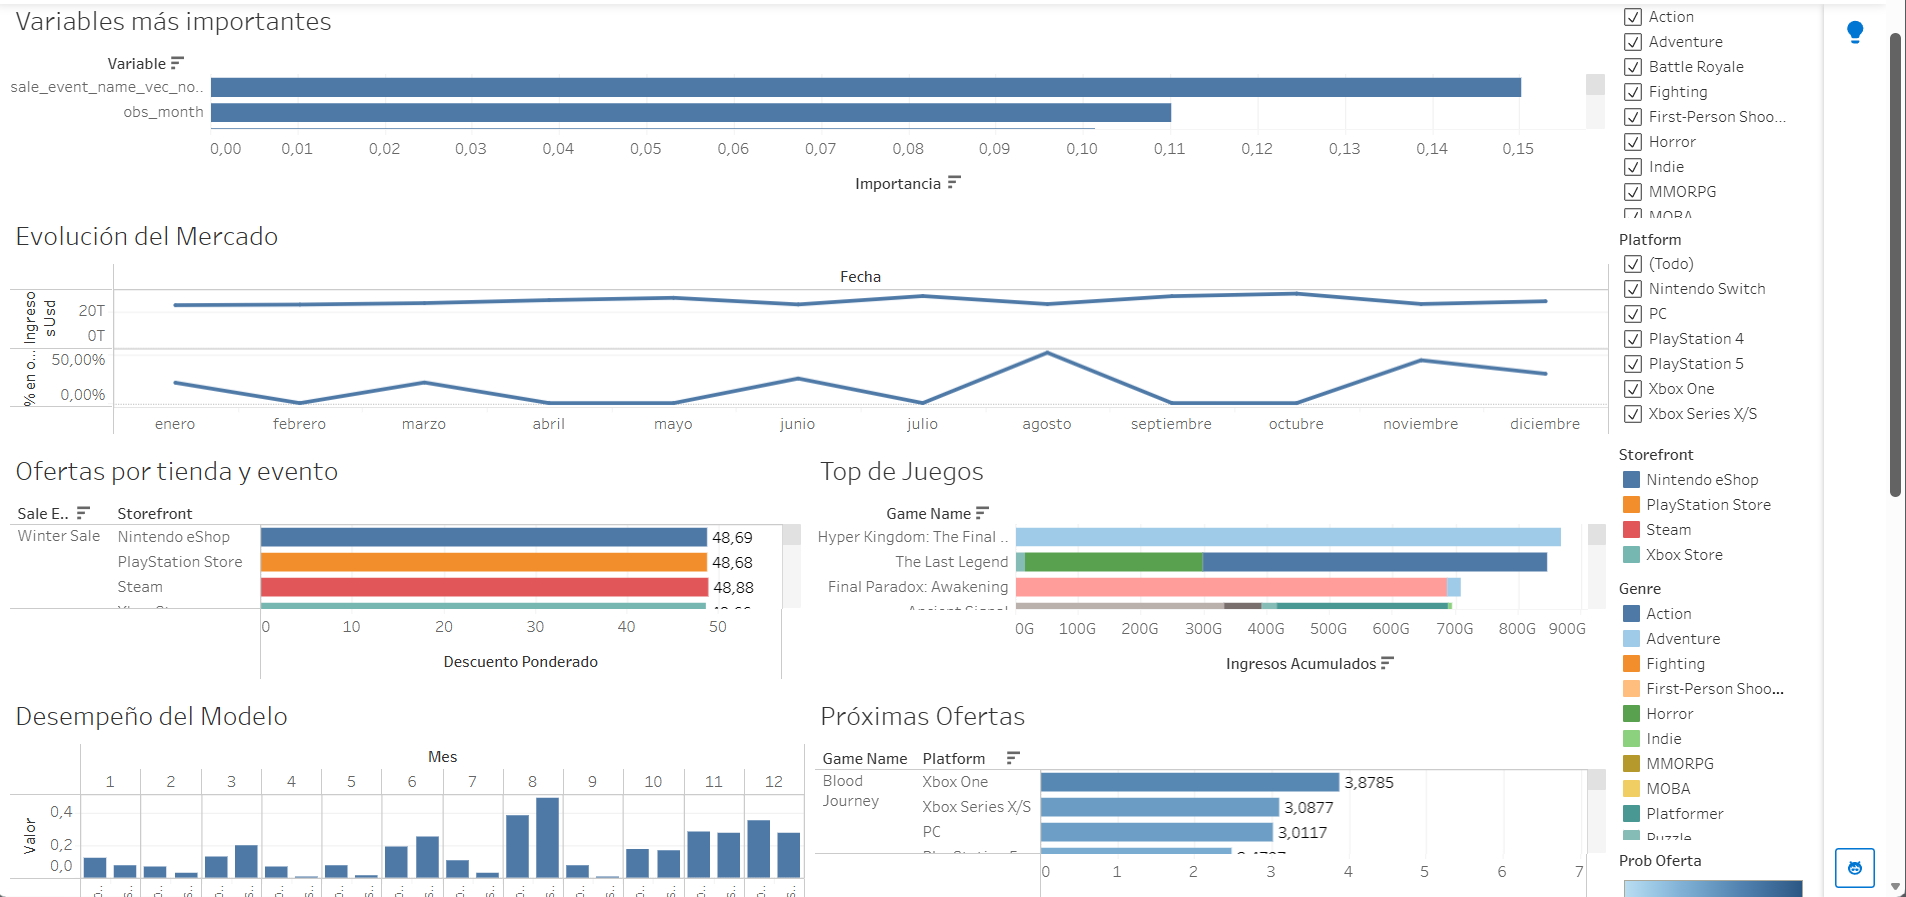

- Evolución del mercado: El porcentaje de ofertas por mes repite el patrón estacional del notebook, con el pico más alto en agosto y otros picos en noviembre y diciembre.
- Ofertas por tienda y evento: El descuento ponderado de Winter Sale es casi idéntico en todas las tiendas (48.7%), lo que confirma que la tienda no diferencia el comportamiento de las ofertas.
- Variables más importantes: Destacan el no-evento y el mes, igual que en la gráfica del Paso 11.
- Desempeño del modelo: Las barras por mes se concentran en los meses donde hay más ofertas (marzo, junio, agosto, noviembre y diciembre), lo que indica que el modelo sigue el patrón estacional de las ofertas reales.
- Valor del tablero: Convierte el análisis agregado en una herramienta de consulta, un consumidor puede revisar cuándo suele bajar de precio un género o plataforma, y una editora puede revisar qué eventos ofrecen mejor descuento.

### Conclusiones

1. Cuándo se compra importa más que qué se compra, las ofertas se concentran en pocos meses (agosto ≈ 51%, noviembre ≈ 44%, diciembre ≈ 31%) y casi no existen en 6 de los 12. El evento activo y el mes son las variables más importantes del modelo; género, plataforma y tienda casi no influyen.
2. Predecir el inicio de una oferta es lo difícil. Una oferta activa continúa en la siguiente observación solo 50% de las veces, y 49.7% de las ofertas empiezan desde un estado sin oferta. Por eso copiar el estado actual no es suficiente.
3. El modelo ordena bien, pero clasifica de forma conservadora. AUC-ROC de 0.82 y AUC-PR de 0.42 muestran buena capacidad de ordenamiento, con el umbral de 0.5 la precisión es de 55% pero el recall solo de 26%. El accuracy de 85% apenas supera al 84.3% de la regla trivial y en F1 de la clase oferta, el baseline queda por encima.
4. El ajuste de hiperparámetros dio una mejora real pero pequeña (AUC +0.008) a un costo de 50% más de entrenamiento, el límite está en la información y el umbral, no en la complejidad del modelo.
5. La parte de Big Data funcionó como se planteó, el CSV de 4.64 GB pasó a 0.80 GB en Parquet, el pipeline de Spark (indexado, codificación, imputación, ensamblado y modelo) se entrenó sobre 4.2 millones de filas, y el modelo se guardó, se recargó y se usó para predecir sobre datos nuevos.

### Repositorio de Github

https://github.com/AIPorDefinir/ai-model-tutsipink/blob/main/src/bigdata/visualizacion/a01711368_alfredo_soto.ipynb